# Phase 8 - Model Evaluation

Project: **Sentiment Analysis with Facebook**

Evaluate the saved pipeline on the held-out test split.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
from src import config
from src.data.load_data import load_raw, inspect_dataset
from src.data.preprocess import prepare_dataframe, clean_text
from src.models.predict import SentimentPredictor
from src.models.evaluate import compute_metrics
from sklearn.metrics import classification_report

In [2]:
df = pd.read_csv(config.DATA_PROCESSED / 'prepared_dataset.csv')
test = df[df['split'] == 'test']
pred = SentimentPredictor()
yhat = [p['sentiment'] for p in pred.predict_many(test['text'].tolist())]
print(classification_report(test['sentiment'], yhat, digits=3))

              precision    recall  f1-score   support

    negative      0.549     0.420     0.476       119
     neutral      0.510     0.378     0.434       275
    positive      0.553     0.724     0.627       322

    accuracy                          0.541       716
   macro avg      0.538     0.507     0.513       716
weighted avg      0.536     0.541     0.528       716



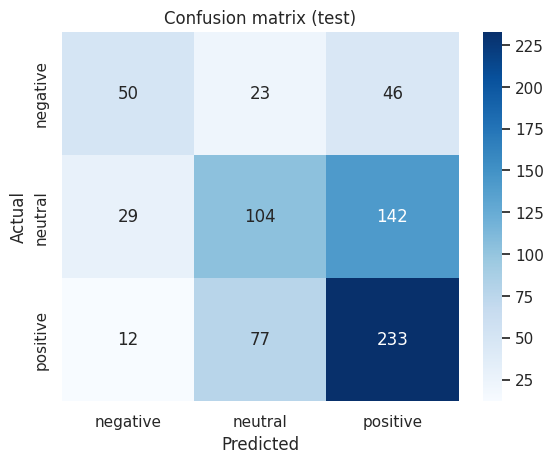

In [3]:
m = compute_metrics(test['sentiment'], yhat)
sns.heatmap(m['confusion_matrix'], annot=True, fmt='d', cmap='Blues', xticklabels=config.LABELS, yticklabels=config.LABELS)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix (test)'); plt.show()

In [4]:
ev = json.loads(config.EVALUATION_PATH.read_text(encoding='utf-8'))
print(ev['overfitting_check']['verdict'])
print(ev['success_criteria'])

Small gap: no strong sign of overfitting.
{'criterion_1': 'Final model beats the majority-class baseline on test macro-F1', 'criterion_1_met': True, 'criterion_2': 'Test accuracy stays below the label-consistency ceiling (sanity check against leakage)', 'label_consistency_ceiling_accuracy_pct': 70.08, 'criterion_2_met': True}
